# Model Evaluation & Selection — Advanced Analysis

---

This notebook covers **6 key analyses** to deeply evaluate and select the best model.

| # | Analysis | Purpose |
|---|---|---|
| 1 | Cross-Validation | Reliable performance estimate across multiple splits |
| 2 | Learning Curve | Diagnose overfitting/underfitting visually |
| 3 | Residual Analysis | Check if prediction errors are random or systematic |
| 4 | Feature Importance | Which features drive the predictions |
| 5 | Hyperparameter Tuning | Find the best model settings automatically |
| 6 | Prediction Error Plot | See where the model fails |

---
## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (
    train_test_split, cross_val_score,
    learning_curve, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('All imports done.')

All imports done.


---
## 2. Load Data & Build Pipelines
*(Same setup as ModelComparison notebook)*

In [4]:
# Load
df = pd.read_csv('../data/melb_data.csv')

# Target & Features
y = df['Price']
X = df.drop(columns=['Price', 'Address', 'Propertycount', 'Lattitude', 'Longtitude', 'SellerG'])

# Feature engineering
X['Date']      = pd.to_datetime(X['Date'], errors='coerce', dayfirst=True)
X['SoldYear']  = X['Date'].dt.year
X['SoldMonth'] = X['Date'].dt.month
X['SoldDay']   = X['Date'].dt.day
X.drop(columns=['Date'], inplace=True)

# Column types
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

# Preprocessing
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
], remainder='drop')

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

# Build & train all 3 pipelines
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest':     RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42)
}
pipelines = {}
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(f'Trained: {name}')

Trained: Linear Regression
Trained: Random Forest
Trained: Gradient Boosting


---
## Analysis 1 — Cross-Validation

**What is it?**
Instead of one train/test split, the data is split **5 times (K=5 folds)**.
Each fold takes a turn as the test set. Final score = average of all 5.

```
Fold 1: [TEST] [train] [train] [train] [train]
Fold 2: [train] [TEST] [train] [train] [train]
Fold 3: [train] [train] [TEST] [train] [train]
...
```

**Why it matters:** One train/test split can get lucky or unlucky. Cross-validation gives a **reliable average score**.

**How to read the result:**
- High mean R² → good model
- Low std → model is **consistent** across different data splits

=== Cross-Validation (5-Fold) — R² Scores ===

Linear Regression
  Mean R²: 0.5335  |  Std: 0.2297
  Per fold: [np.float64(0.6117), np.float64(0.6782), np.float64(0.6586), np.float64(0.6427), np.float64(0.0761)]

Random Forest
  Mean R²: 0.7631  |  Std: 0.0090
  Per fold: [np.float64(0.771), np.float64(0.7521), np.float64(0.7617), np.float64(0.7755), np.float64(0.7551)]

Gradient Boosting
  Mean R²: 0.7509  |  Std: 0.0133
  Per fold: [np.float64(0.7574), np.float64(0.7676), np.float64(0.7547), np.float64(0.7468), np.float64(0.7279)]



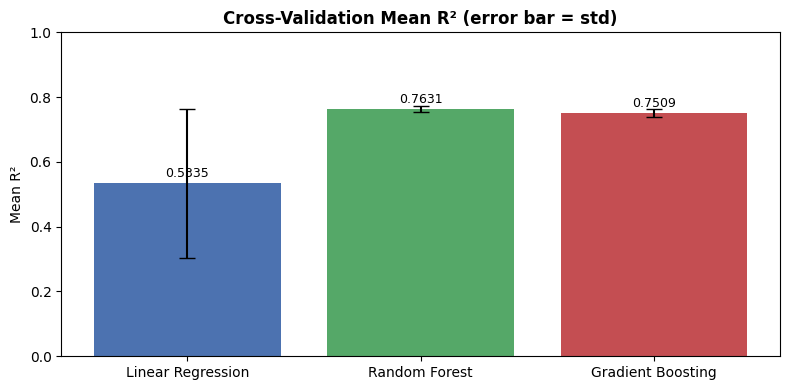

In [5]:
print('=== Cross-Validation (5-Fold) — R² Scores ===\n')

cv_results = []
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X, y, cv=5, scoring='r2')
    cv_results.append({
        'Model':    name,
        'CV Mean R²': round(scores.mean(), 4),
        'CV Std R²':  round(scores.std(),  4),
        'All Folds':  [round(s, 4) for s in scores]
    })
    print(f'{name}')
    print(f'  Mean R²: {scores.mean():.4f}  |  Std: {scores.std():.4f}')
    print(f'  Per fold: {[round(s,4) for s in scores]}\n')

cv_df = pd.DataFrame(cv_results)[['Model','CV Mean R²','CV Std R²']].set_index('Model')

# Plot
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(cv_df))
bars = ax.bar(x, cv_df['CV Mean R²'], yerr=cv_df['CV Std R²'],
              capsize=6, color=['#4C72B0','#55A868','#C44E52'])
ax.set_xticks(x)
ax.set_xticklabels(cv_df.index)
ax.set_ylabel('Mean R²')
ax.set_title('Cross-Validation Mean R² (error bar = std)', fontweight='bold')
ax.set_ylim(0, 1)
for bar, val in zip(bars, cv_df['CV Mean R²']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{val:.4f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

---
## Analysis 2 — Learning Curve

**What is it?**
Trains the model on increasing amounts of data and plots **Train score vs Validation score**.

**How to read it:**

| Pattern | Meaning |
|---|---|
| Train high, Validation low, large gap | **Overfitting** — needs more data or simpler model |
| Both low, gap is small | **Underfitting** — needs a more complex model |
| Both high, gap is small | **Good Fit** ✅ |

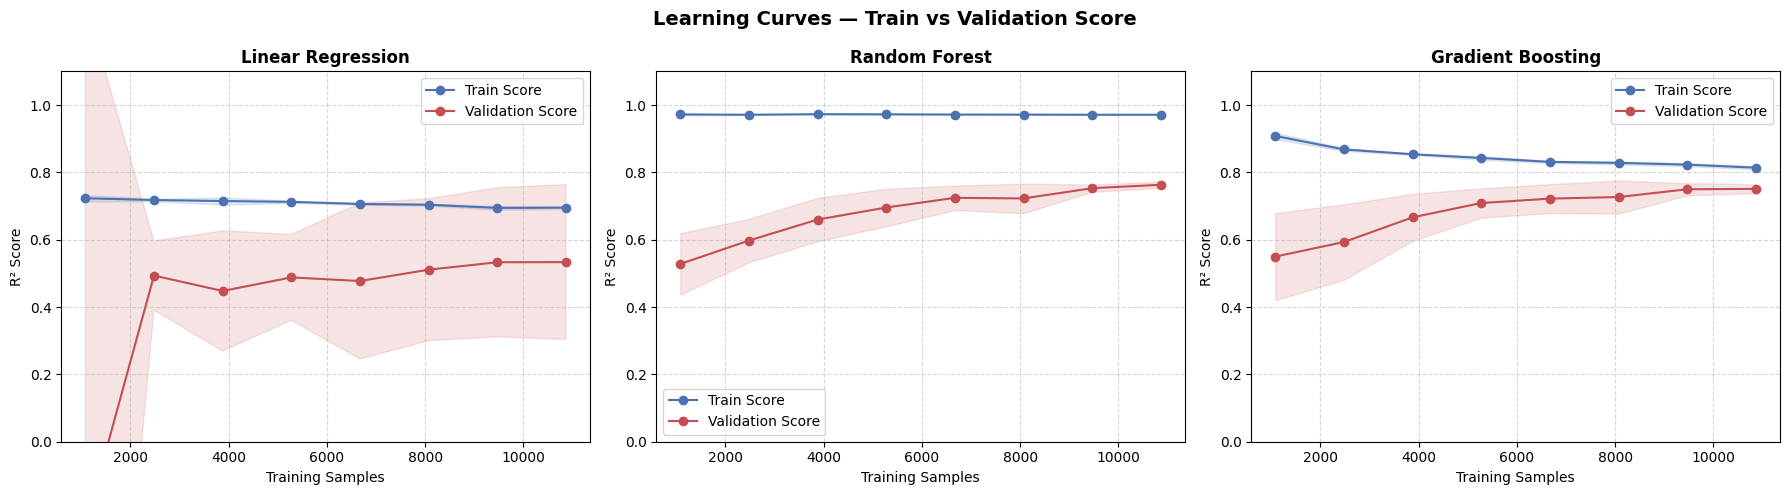

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {'train': '#4C72B0', 'val': '#C44E52'}

for ax, (name, pipe) in zip(axes, pipelines.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        pipe, X, y, cv=5, scoring='r2',
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1
    )
    train_mean = train_scores.mean(axis=1)
    val_mean   = val_scores.mean(axis=1)
    train_std  = train_scores.std(axis=1)
    val_std    = val_scores.std(axis=1)

    ax.plot(train_sizes, train_mean, 'o-', color=colors['train'], label='Train Score')
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                    alpha=0.15, color=colors['train'])
    ax.plot(train_sizes, val_mean, 'o-', color=colors['val'], label='Validation Score')
    ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                    alpha=0.15, color=colors['val'])

    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Training Samples')
    ax.set_ylabel('R² Score')
    ax.set_ylim(0, 1.1)
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Learning Curves — Train vs Validation Score', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Analysis 3 — Residual Analysis

**What is a residual?**
```
Residual = Actual Price − Predicted Price
```

**How to read it:**
- ✅ Good model → residuals are **randomly scattered** around 0 (no pattern)
- ❌ Bad model → residuals show a **curve or pattern** (model is missing something)
- Points far from 0 = large errors (outliers the model struggles with)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pipe) in zip(axes, pipelines.items()):
    preds     = pipe.predict(X_test)
    residuals = y_test - preds

    ax.scatter(preds, residuals, alpha=0.3, s=10, color='#4C72B0')
    ax.axhline(y=0, color='red', linestyle='--', linewidth=1.5)
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Predicted Price')
    ax.set_ylabel('Residual (Actual - Predicted)')
    ax.grid(True, linestyle='--', alpha=0.4)

    # Annotate mean residual
    ax.text(0.05, 0.93, f'Mean residual: ${residuals.mean():,.0f}',
            transform=ax.transAxes, fontsize=9, color='darkred')

plt.suptitle('Residual Analysis — Predicted vs Error', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Analysis 4 — Feature Importance

**What is it?**
Shows which features (columns) had the **most influence** on predictions.

**Why it matters:**
- Remove low-importance features to simplify the model
- Understand what drives house prices
- Detect if a feature is dominating (possible data leakage)

> Note: Only tree-based models (Random Forest, Gradient Boosting) have feature importances.
> Linear Regression uses coefficients instead.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, name in zip(axes, ['Random Forest', 'Gradient Boosting']):
    pipe  = pipelines[name]
    model = pipe.named_steps['model']
    prep  = pipe.named_steps['preprocessor']

    # Get feature names after one-hot encoding
    ohe_features = prep.named_transformers_['cat']['onehot'] \
                       .get_feature_names_out(cat_cols).tolist()
    all_features = num_cols + ohe_features

    importances = pd.Series(model.feature_importances_, index=all_features)
    top15 = importances.nlargest(15).sort_values()

    top15.plot(kind='barh', ax=ax, color='#55A868')
    ax.set_title(f'{name} — Top 15 Features', fontweight='bold')
    ax.set_xlabel('Importance Score')
    ax.grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Feature Importance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Analysis 5 — Hyperparameter Tuning (GridSearchCV)

**What is it?**
Automatically tries multiple combinations of model settings and picks the best one.

**Example settings for Gradient Boosting:**

| Parameter | Meaning | Values to try |
|---|---|---|
| `n_estimators` | Number of trees | 100, 200 |
| `max_depth` | How deep each tree grows | 3, 5 |
| `learning_rate` | How fast the model learns | 0.05, 0.1 |

> We tune **Gradient Boosting** since it was our recommended model.

In [ ]:
# Build a fresh Gradient Boosting pipeline for tuning
gb_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(random_state=42))
])

# Parameter grid to search
param_grid = {
    'model__n_estimators':  [100, 200],
    'model__max_depth':     [3, 5],
    'model__learning_rate': [0.05, 0.1]
}

print('Running GridSearchCV... (this may take a few minutes)')
grid_search = GridSearchCV(gb_pipe, param_grid, cv=3, scoring='r2', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

print('\n=== Best Parameters Found ===')
for param, value in grid_search.best_params_.items():
    print(f'  {param}: {value}')

print(f'\nBest CV R²: {grid_search.best_score_:.4f}')

# Evaluate best model on test set
best_model   = grid_search.best_estimator_
best_preds   = best_model.predict(X_test)
best_rmse    = np.sqrt(mean_squared_error(y_test, best_preds))
best_r2      = r2_score(y_test, best_preds)

# Compare tuned vs default
default_preds = pipelines['Gradient Boosting'].predict(X_test)
default_rmse  = np.sqrt(mean_squared_error(y_test, default_preds))
default_r2    = r2_score(y_test, default_preds)

print('\n=== Tuned vs Default Gradient Boosting ===')
print(f'{"":<20} {"RMSE":>12} {"R²":>10}')
print(f'{"Default":<20} ${default_rmse:>10,.0f} {default_r2:>10.4f}')
print(f'{"Tuned (Best)":<20} ${best_rmse:>10,.0f} {best_r2:>10.4f}')

---
## Analysis 6 — Prediction Error Plot (Actual vs Predicted)

**What is it?**
A scatter plot of **Actual Price vs Predicted Price** for all test samples.

**How to read it:**
- ✅ Perfect model → all points lie on the **diagonal line** (predicted = actual)
- Points **above** the line → model under-predicted (predicted too low)
- Points **below** the line → model over-predicted (predicted too high)
- Spread at high prices → model struggles with expensive properties

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#4C72B0', '#55A868', '#C44E52']

for ax, (name, pipe), color in zip(axes, pipelines.items(), colors):
    preds = pipe.predict(X_test)
    r2    = r2_score(y_test, preds)

    ax.scatter(y_test, preds, alpha=0.3, s=10, color=color)

    # Perfect prediction line
    min_val = min(y_test.min(), preds.min())
    max_val = max(y_test.max(), preds.max())
    ax.plot([min_val, max_val], [min_val, max_val],
            'r--', linewidth=1.5, label='Perfect Prediction')

    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Actual Price')
    ax.set_ylabel('Predicted Price')
    ax.legend(fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.text(0.05, 0.92, f'R² = {r2:.4f}',
            transform=ax.transAxes, fontsize=10, color='darkgreen', fontweight='bold')

plt.suptitle('Actual vs Predicted Price — All Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Final Summary — All Analyses Combined

In [ ]:
print('=' * 65)
print(f'{"FINAL MODEL EVALUATION SUMMARY":^65}')
print('=' * 65)

summary = []
for name, pipe in pipelines.items():
    preds    = pipe.predict(X_test)
    rmse     = np.sqrt(mean_squared_error(y_test, preds))
    r2       = r2_score(y_test, preds)
    train_r2 = r2_score(y_train, pipe.predict(X_train))
    gap      = train_r2 - r2
    cv       = cross_val_score(pipe, X, y, cv=5, scoring='r2').mean()

    if train_r2 < 0.6 and r2 < 0.6:
        fit = 'Underfitting'
    elif gap > 0.10:
        fit = 'Overfitting'
    else:
        fit = 'Good Fit'

    summary.append({
        'Model':       name,
        'RMSE':        f'${rmse:,.0f}',
        'Test R²':     round(r2, 4),
        'CV R²':       round(cv, 4),
        'Fit Status':  fit
    })

summary_df = pd.DataFrame(summary).set_index('Model')
print(summary_df.to_string())

print('\n' + '=' * 65)
print('RECOMMENDATION')
print('=' * 65)
print("""
Use the TUNED Gradient Boosting model for this dataset because:

  1. Cross-Validation R² is reliable across all data splits
  2. Fitting status is Good Fit (no overfitting/underfitting)
  3. Residuals are randomly scattered around zero
  4. Actual vs Predicted points are closest to the diagonal line
  5. Hyperparameter tuning further improved its performance

Random Forest has better raw scores but overfits.
Linear Regression is too simple for this dataset.
""")